- Motion check between pre-bleach and first post-bleach frame
  (gained signal outside each droplet; moved droplets excluded)
- Relative drop map without background subtraction (background clipped at 0)
- Bleached droplets selected by peak relative drop
- Spot defined at a fraction of each droplet's peak drop; fractions compared visually

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
from skimage import filters, measure
from skimage.segmentation import find_boundaries, expand_labels
from scipy import ndimage as ndi

# 0. Load data and create helper functions

In [2]:
SEG_DIR = Path("results/segmentation")
FRAME_PRE, FRAME_POST = 0, 1        # pre-bleach frame and first post-bleach frame
 
files = sorted(Path("data").glob("*.tif"))
stacks, droplet_labels = {}, {}
for f in files:
    stacks[f.stem] = tifffile.imread(f).astype(np.float64)
    droplet_labels[f.stem] = tifffile.imread(SEG_DIR / f"{f.stem}_droplet_labels.tif")
    print(f"{f.stem}: {droplet_labels[f.stem].max()} droplets")
 
with open(SEG_DIR / "segmentation_parameters.json") as fh:
    print("segmentation parameters:", json.load(fh))

Apt2+Ca_2: 115 droplets
Apt2_1: 49 droplets
PEG_3: 44 droplets
segmentation parameters: {'sigma': 0.5, 'kernel_size': 64, 'clip_limit': 0.01, 'min_droplet_area': 150, 'min_peak_distance': 6}


In [3]:
def relative_drop(pre, post, labels, sigma=1.0):
    """Fraction of the pre-bleach signal lost in the first post-bleach frame, pixel by pixel,
    after light smoothing (to reduce single-frame noise). 1 = fully bleached, 0 = unchanged.
    Set to 0 outside droplets. No background subtraction: the microscope clips the background at 0."""

    pre_s = filters.gaussian(pre, sigma=sigma, preserve_range=True)
    post_s = filters.gaussian(post, sigma=sigma, preserve_range=True)
    drop = (pre_s - post_s) / np.maximum(pre_s, 1e-6)
    drop[labels == 0] = 0
    return drop
 
 
def droplet_drop_table(drop, labels):
    """For every droplet: its size and how strongly its most-bleached part dropped."""

    rows = []
    for r in measure.regionprops(labels):
        vals = drop[r.slice][r.image]
        rows.append({"droplet": r.label, "area": r.area,
                     "peak_drop": np.percentile(vals, 95),   # robust maximum
                     "mean_drop": vals.mean()})
    return pd.DataFrame(rows)
 
 
def bleach_spot(drop, labels, droplet_id, fraction=0.5):
    """Bleached spot of one droplet: pixels whose drop is at least `fraction` of the droplet's
    peak drop (fraction=0.5 = half maximum). Largest connected region, holes filled."""
    
    inside = labels == droplet_id
    peak = np.percentile(drop[inside], 95)
    spot = inside & (drop >= fraction * peak)
    lab = measure.label(spot, connectivity=2)
    if lab.max() > 1:
        sizes = np.bincount(lab.ravel()); sizes[0] = 0
        spot = lab == sizes.argmax()
    return ndi.binary_fill_holes(spot) & inside


def droplet_motion(pre, post, labels, sigma=1.0, territory=5, gain_frac=0.25):
    """For every droplet, the signal gained just outside it between pre and post.
    - ring: pixels within `territory` pixels outside the droplet, without entering the territory of neighbouring droplets (expand_labels)
    - gained pixel: post - pre larger than `gain_frac` x the droplet's median pre-bleach intensity
    - shift_px: number of gained pixels divided by the droplet diameter. When a disc moves by a few pixels, the newly covered crescent 
      has an area of about diameter x displacement, so this is a rough estimate of the displacement in pixels (0 for a droplet that stayed)."""
    
    pre_s = filters.gaussian(pre, sigma=sigma, preserve_range=True)
    post_s = filters.gaussian(post, sigma=sigma, preserve_range=True)
    terr = expand_labels(labels, distance=territory)
    rows = []
    for r in measure.regionprops(terr):
        sl, own = r.slice, r.image                    # bounding box and territory of this droplet
        droplet = labels[sl] == r.label
        ring = own & ~droplet                         # the band around the droplet where gained signal is looked for
        level = np.median(pre_s[sl][droplet])
        gained = ring & ((post_s[sl] - pre_s[sl]) > gain_frac * level)
        diameter = 2 * np.sqrt(droplet.sum() / np.pi)
        rows.append({"droplet": r.label, "gain_px": int(gained.sum()), "shift_px": gained.sum() / diameter})
    return pd.DataFrame(rows)

# 1. Motion Check

A droplet that moves between the pre-bleach and the first post-bleach frame leaves a dark area where it used to be, which looks like bleaching. This section handles movement before deciding which droplets are bleached by checking for gained signal in a thin ring just outside each droplet.

In [4]:
# estimated shift of every droplet
# Droplets that stayed have a shift close to 0; droplets that moved stand out.

SMOOTH_SIGMA = 1.0
TERRITORY = 5
GAIN_FRAC = 0.25     # a pixel counts as "gained" if it brightened by more than 25% of the droplet intensity
MAX_SHIFT = 1     # pixels
 
motion = {}
for name, stack in stacks.items():
    motion[name] = droplet_motion(stack[FRAME_PRE], stack[FRAME_POST], droplet_labels[name],
                                  sigma=SMOOTH_SIGMA, territory=TERRITORY, gain_frac=GAIN_FRAC)
    motion[name]["moved"] = motion[name]["shift_px"] > MAX_SHIFT

for name, mot in motion.items():
    print(f"\n{name}: moved droplets")
    print(mot[mot["moved"]].round(2).to_string(index=False))


Apt2+Ca_2: moved droplets
Empty DataFrame
Columns: [droplet, gain_px, shift_px, moved]
Index: []

Apt2_1: moved droplets
 droplet  gain_px  shift_px  moved
      16       97      5.74   True

PEG_3: moved droplets
 droplet  gain_px  shift_px  moved
      27       79      3.40   True
      38      152     10.39   True


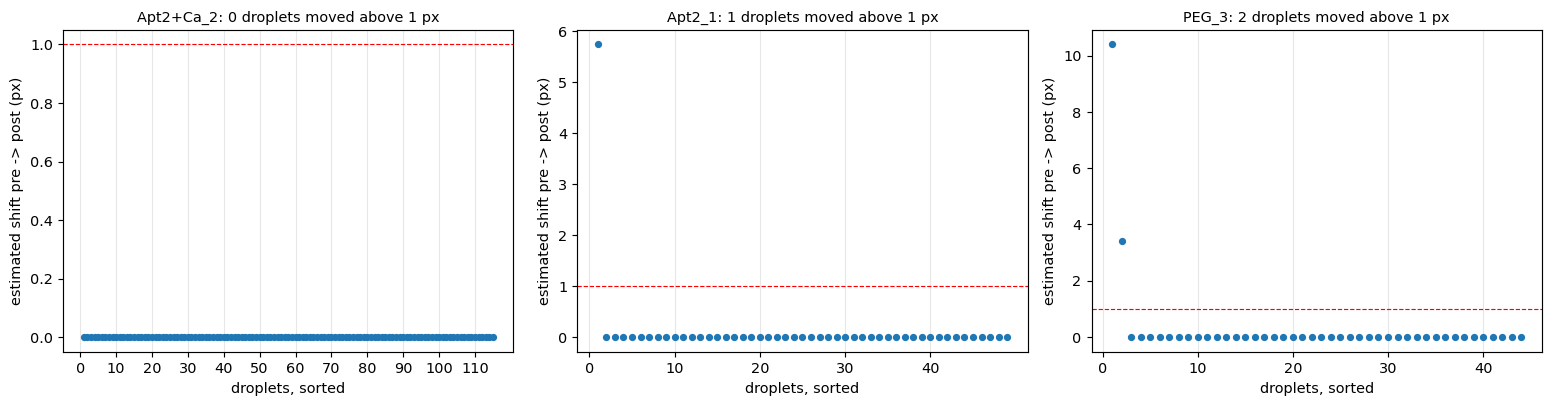

In [5]:
fig, axes = plt.subplots(1, len(motion), squeeze=False, figsize=(5 * len(motion), 4))

for ax, (name, mot) in zip(axes[0], motion.items()):
    vals = np.sort(mot["shift_px"].values)[::-1]
    n_moved = mot["moved"].sum()

    ax.plot(range(1, len(vals) + 1), vals, "o", markersize=4)
    ax.axhline(MAX_SHIFT, color="red", ls="--", lw=0.8)
    ax.set_xticks(range(0, len(vals) + 1, 10)); ax.grid(axis="x", alpha=0.3)

    ax.set_title(f"{name}: {n_moved} droplets moved above {MAX_SHIFT} px", fontsize=10)
    ax.set_xlabel("droplets, sorted"); ax.set_ylabel("estimated shift pre -> post (px)")
plt.tight_layout(); plt.show()

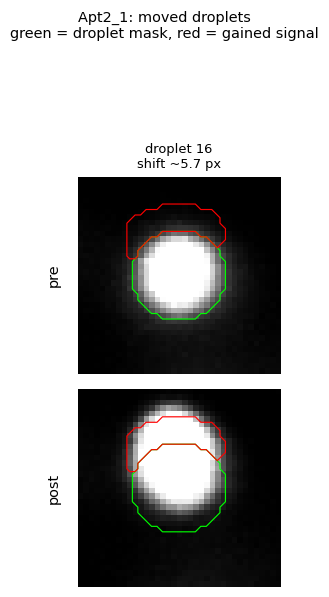

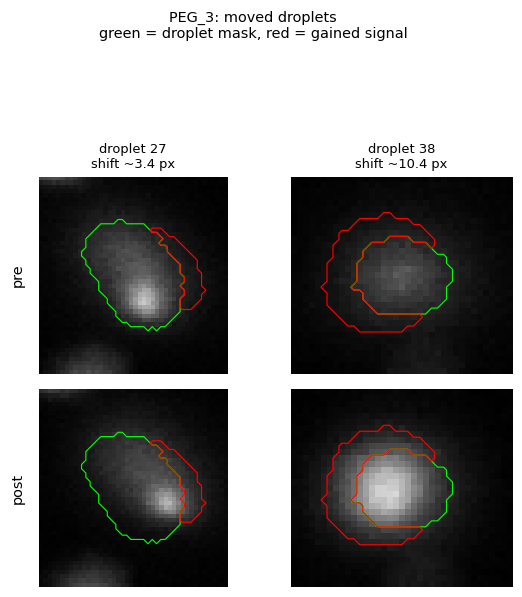

In [6]:
# Green = droplet mask (pre-bleach), red = gained pixels (signal that appeared outside the droplet).

PAD = 10
 
for name, mot in motion.items():
    ids = mot.loc[mot["moved"], "droplet"].tolist()
    if not ids:
        continue
    labels, stack = droplet_labels[name], stacks[name]
    pre, post = stack[FRAME_PRE], stack[FRAME_POST]
    lo, hi = np.percentile(pre, (1, 99.5))
    pre_s = filters.gaussian(pre, sigma=SMOOTH_SIGMA, preserve_range=True)
    post_s = filters.gaussian(post, sigma=SMOOTH_SIGMA, preserve_range=True)
    terr = expand_labels(labels, distance=TERRITORY)               # same territories as in droplet_motion
 
    fig, axes = plt.subplots(2, len(ids), squeeze=False, figsize=(2.8 * len(ids), 5.8))
    for j, d in enumerate(ids):
        r0, c0, r1, c1 = measure.regionprops((labels == d).astype(int))[0].bbox
        sl = (slice(max(r0 - PAD, 0), r1 + PAD), slice(max(c0 - PAD, 0), c1 + PAD))
        droplet = labels[sl] == d
        level = np.median(pre_s[labels == d])
        gained = (terr[sl] == d) & ~droplet & ((post_s[sl] - pre_s[sl]) > GAIN_FRAC * level)

        for i, img in enumerate((pre, post)):
            ax = axes[i, j]
            ax.imshow(img[sl], cmap="gray", vmin=lo, vmax=hi)
            ax.contour(droplet.astype(float), levels=[0.5], colors="lime", linewidths=0.8)
            if gained.any():
                ax.contour(gained.astype(float), levels=[0.5], colors="red", linewidths=0.8)
            ax.axis("off")
        shift = mot.loc[mot["droplet"] == d, "shift_px"].iloc[0]
        axes[0, j].set_title(f"droplet {d}\nshift ~{shift:.1f} px", fontsize=9)

    axes[0, 0].text(-0.15, 0.5, "pre", transform=axes[0, 0].transAxes, rotation=90, va="center")
    axes[1, 0].text(-0.15, 0.5, "post", transform=axes[1, 0].transAxes, rotation=90, va="center")
    fig.suptitle(f"{name}: moved droplets\ngreen = droplet mask, red = gained signal", fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.8 / fig.get_figheight()))
    plt.show()

# 2. Which droplets are bleached?

In [7]:
# Each droplet gets a "peak_drop": how much its most-bleached part lost in the first post-bleach frame.
# Unbleached droplets stay close to 0; bleached ones are clearly higher.

SMOOTH_SIGMA = 1.0

drops, tables = {}, {}
for name, stack in stacks.items():
    drops[name] = relative_drop(stack[FRAME_PRE], stack[FRAME_POST],
                                droplet_labels[name], sigma=SMOOTH_SIGMA)
    tab = droplet_drop_table(drops[name], droplet_labels[name])
    tables[name] = tab.merge(motion[name], on="droplet")

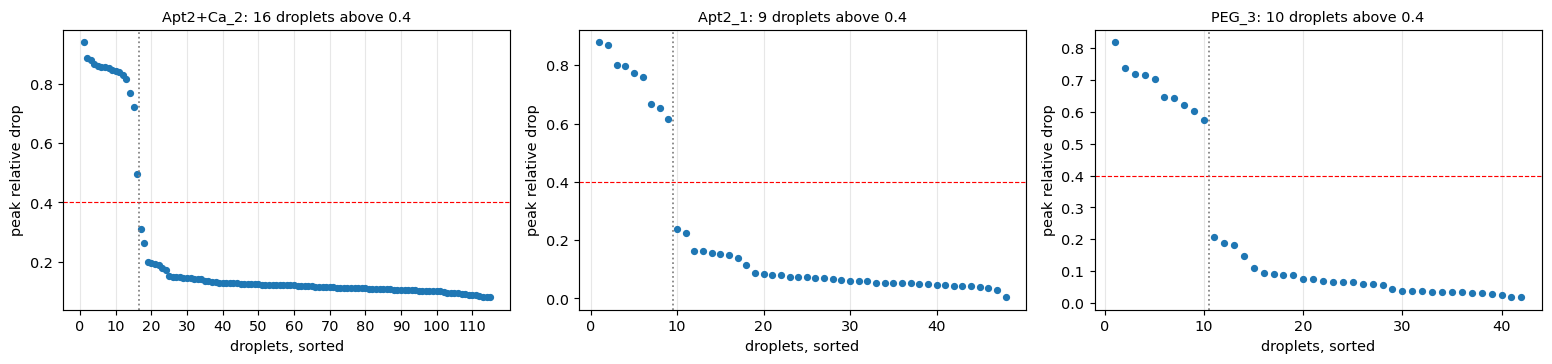

In [8]:
# Set MIN_PEAK_DROP based on the plot inside the gap between the two groups.

MIN_PEAK_DROP = 0.4

fig, axes = plt.subplots(1, len(tables), squeeze=False, figsize=(5 * len(tables), 3.6))
for ax, (name, tab) in zip(axes[0], tables.items()):
    static = tab[~tab["moved"]]
    vals = np.sort(static["peak_drop"].values)[::-1]
    n_bleached = (vals >= MIN_PEAK_DROP).sum()
 
    ax.plot(range(1, len(vals) + 1), vals, "o", markersize=4)
    ax.axhline(MIN_PEAK_DROP, color="red", ls="--", lw=0.8)        # threshold
    ax.axvline(n_bleached + 0.5, color="gray", ls=":", lw=1.2)     # end of the bleached group
    ax.set_xticks(range(0, len(vals) + 1, 10))                     
    ax.grid(axis="x", alpha=0.3)                                   
 
    ax.set_title(f"{name}: {n_bleached} droplets above {MIN_PEAK_DROP}", fontsize=10)
    ax.set_xlabel("droplets, sorted"); ax.set_ylabel("peak relative drop")
plt.tight_layout(); plt.show()

# 2. Chose spot fraction

In [9]:
bleached = {}
for name, tab in tables.items():
    bleached[name] = tab.loc[(tab["peak_drop"] >= MIN_PEAK_DROP) & ~tab["moved"], "droplet"].tolist()

for name, ids in bleached.items():
    print(f"{name}: {len(ids)} bleached droplets")

Apt2+Ca_2: 16 bleached droplets
Apt2_1: 9 bleached droplets
PEG_3: 10 bleached droplets


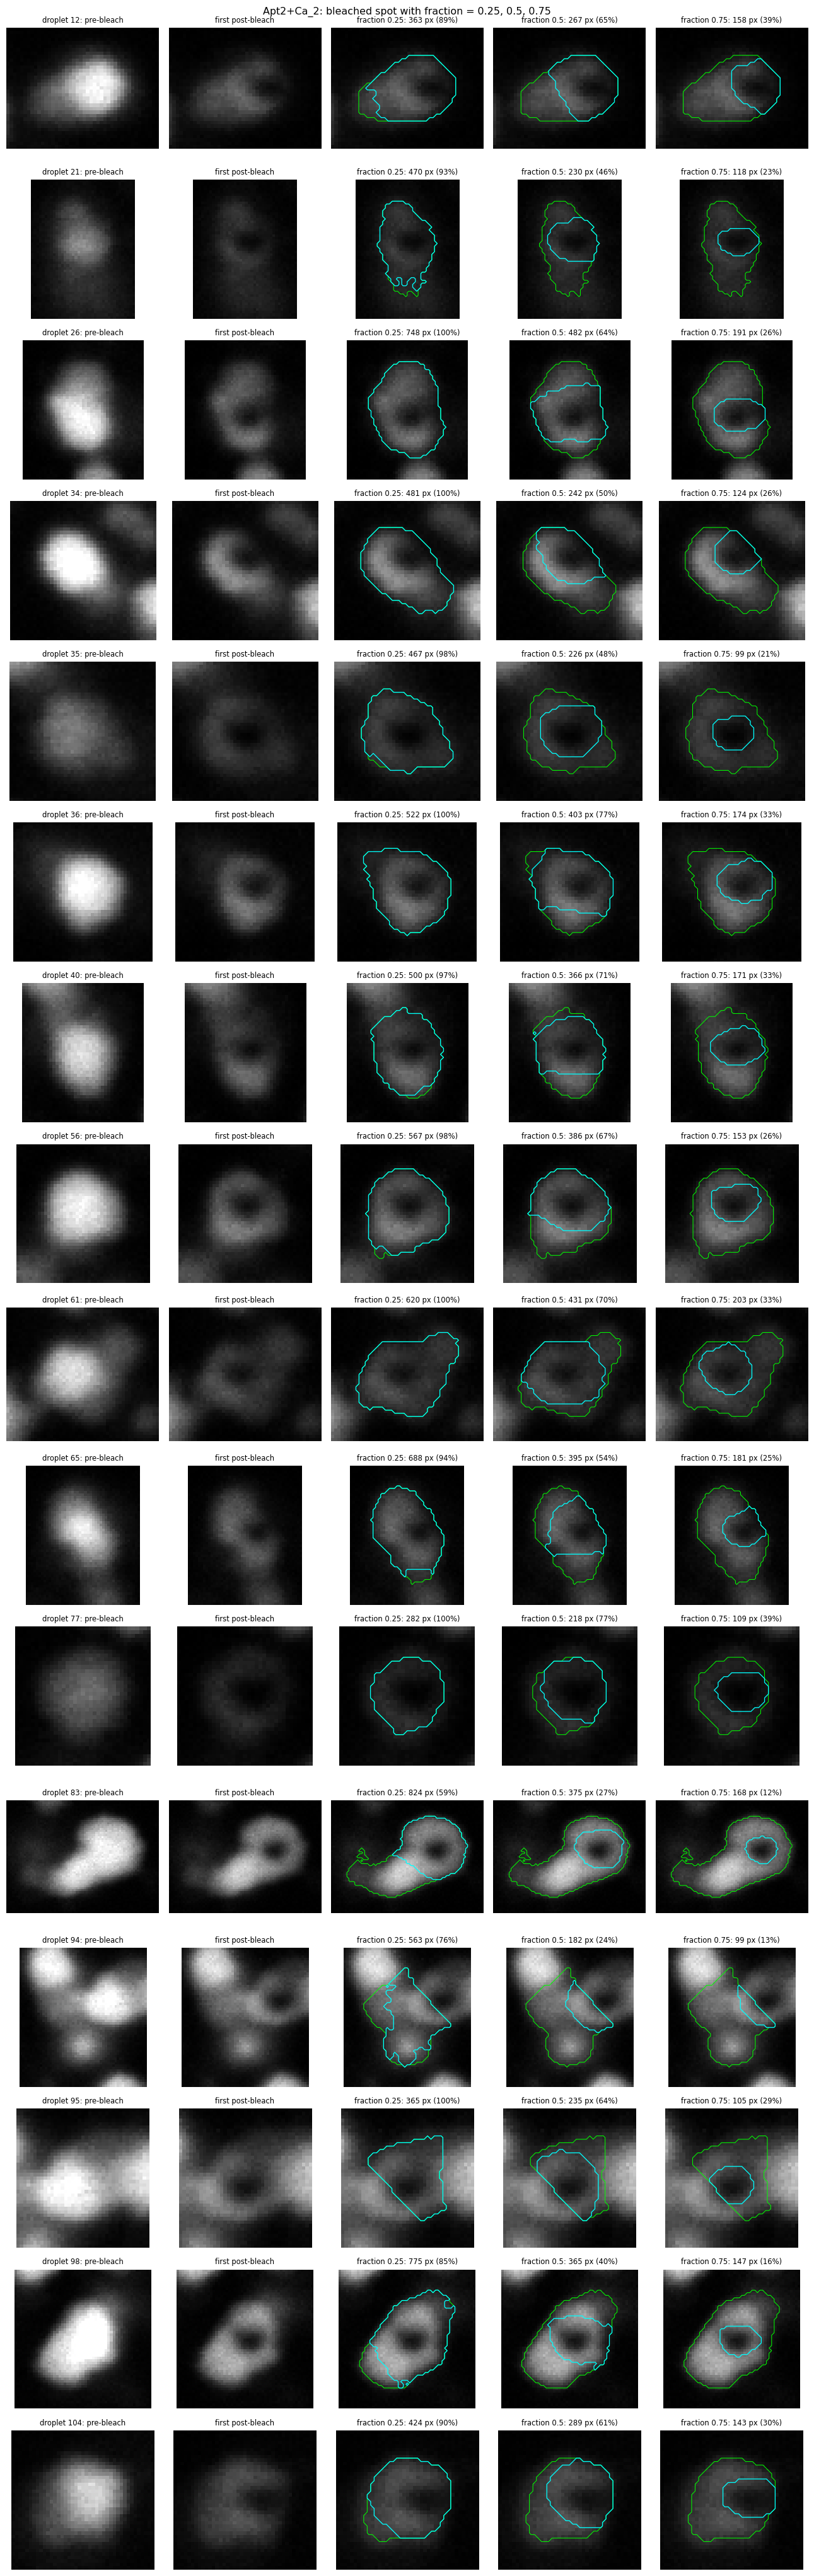

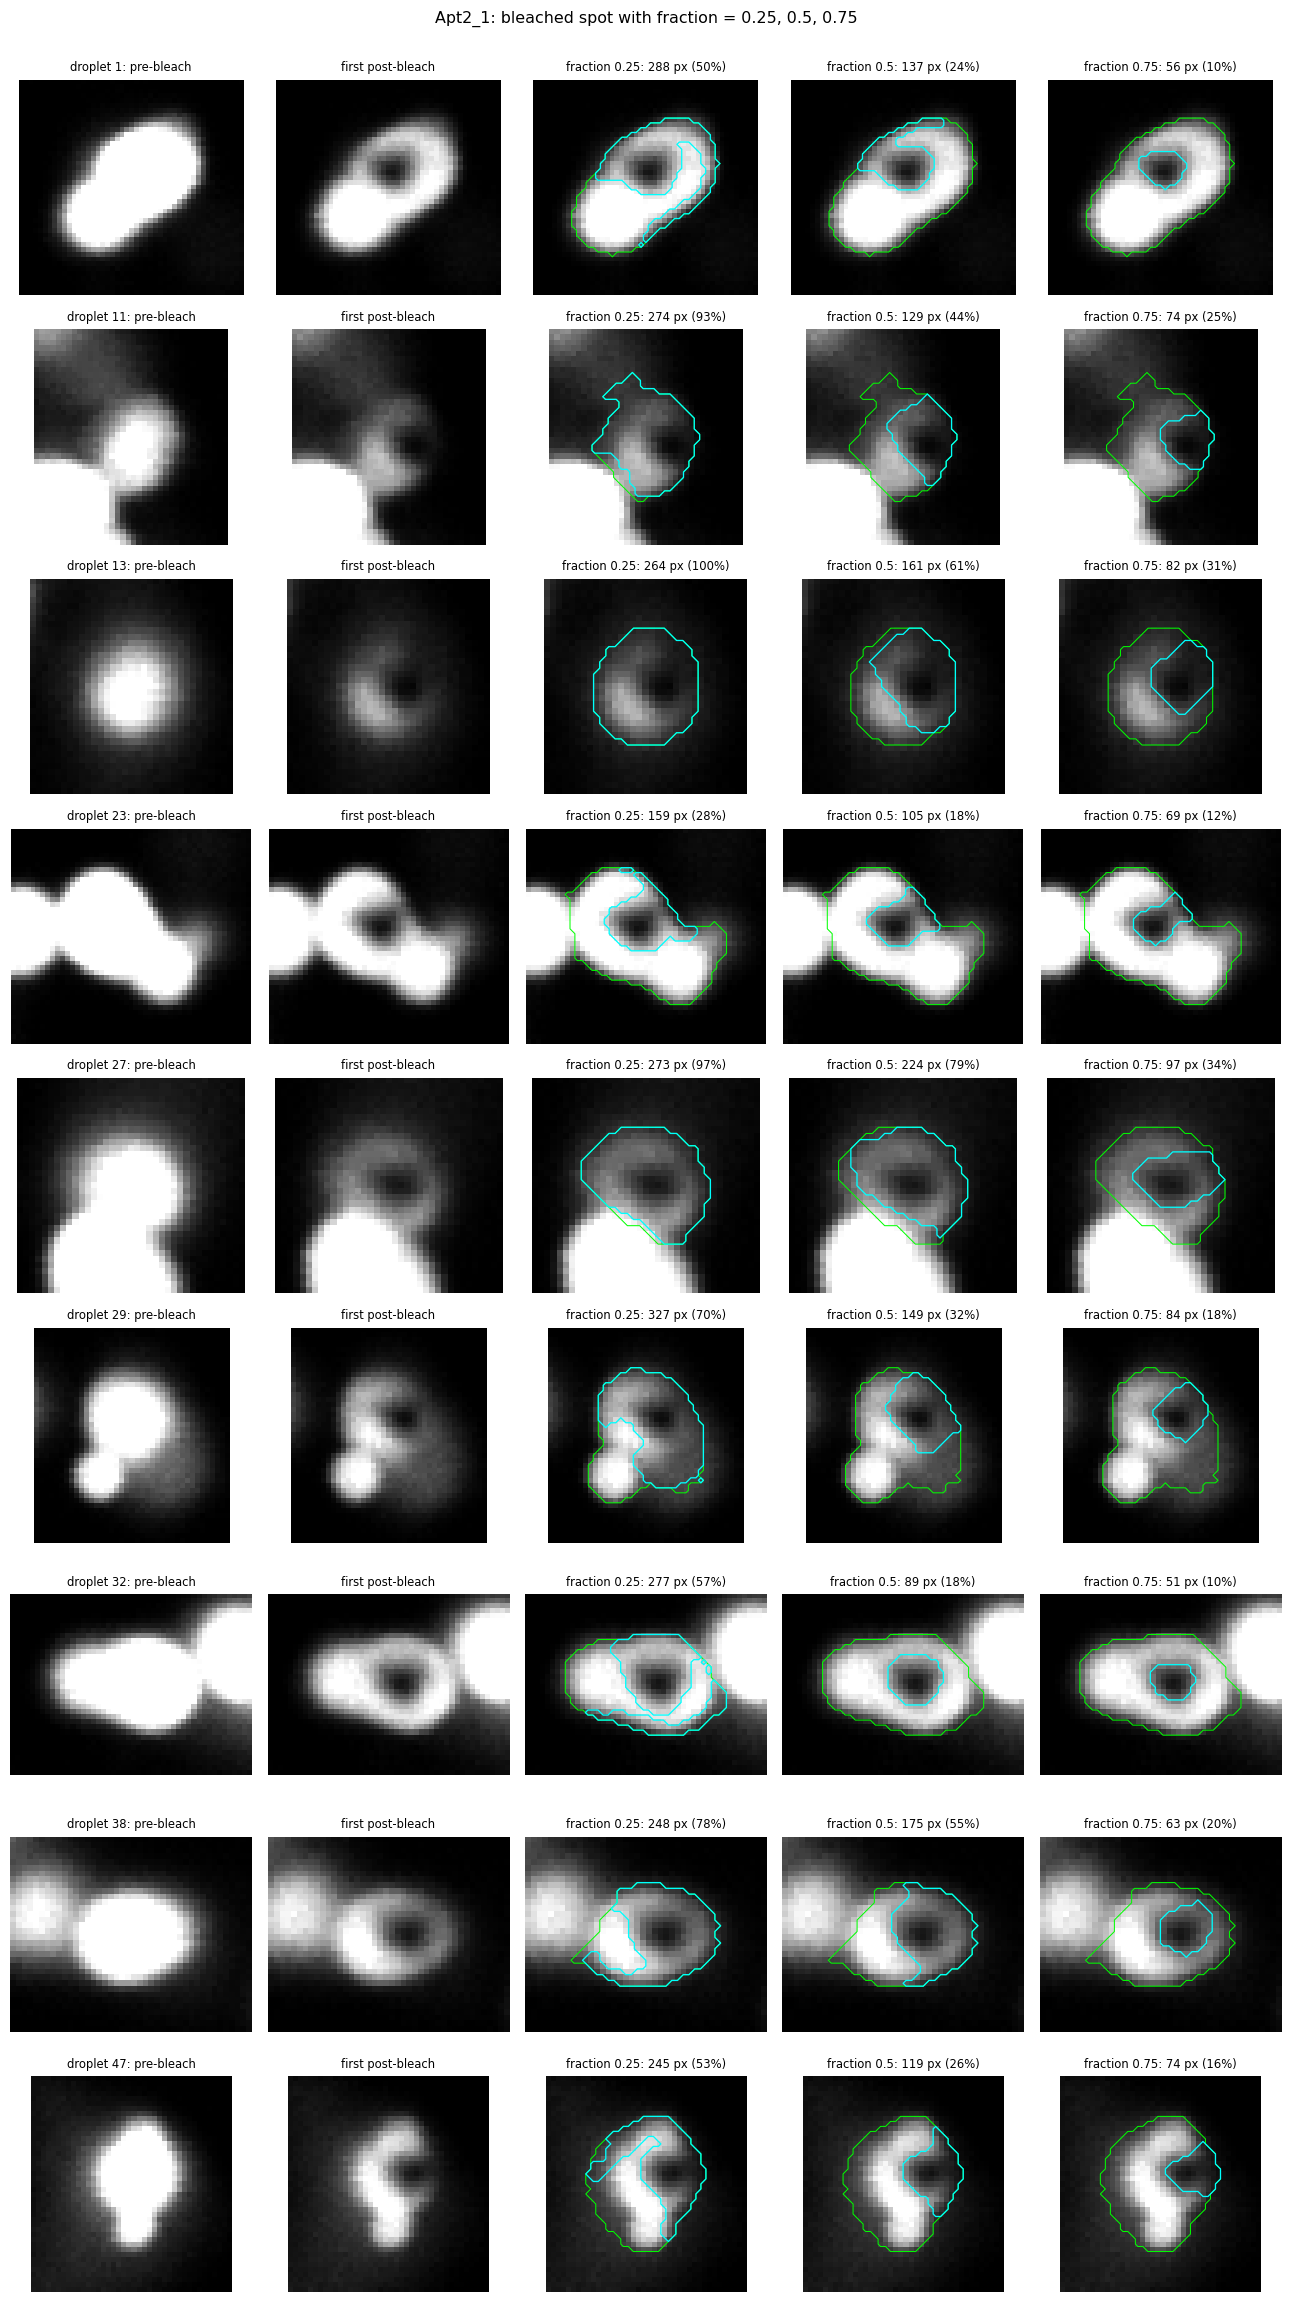

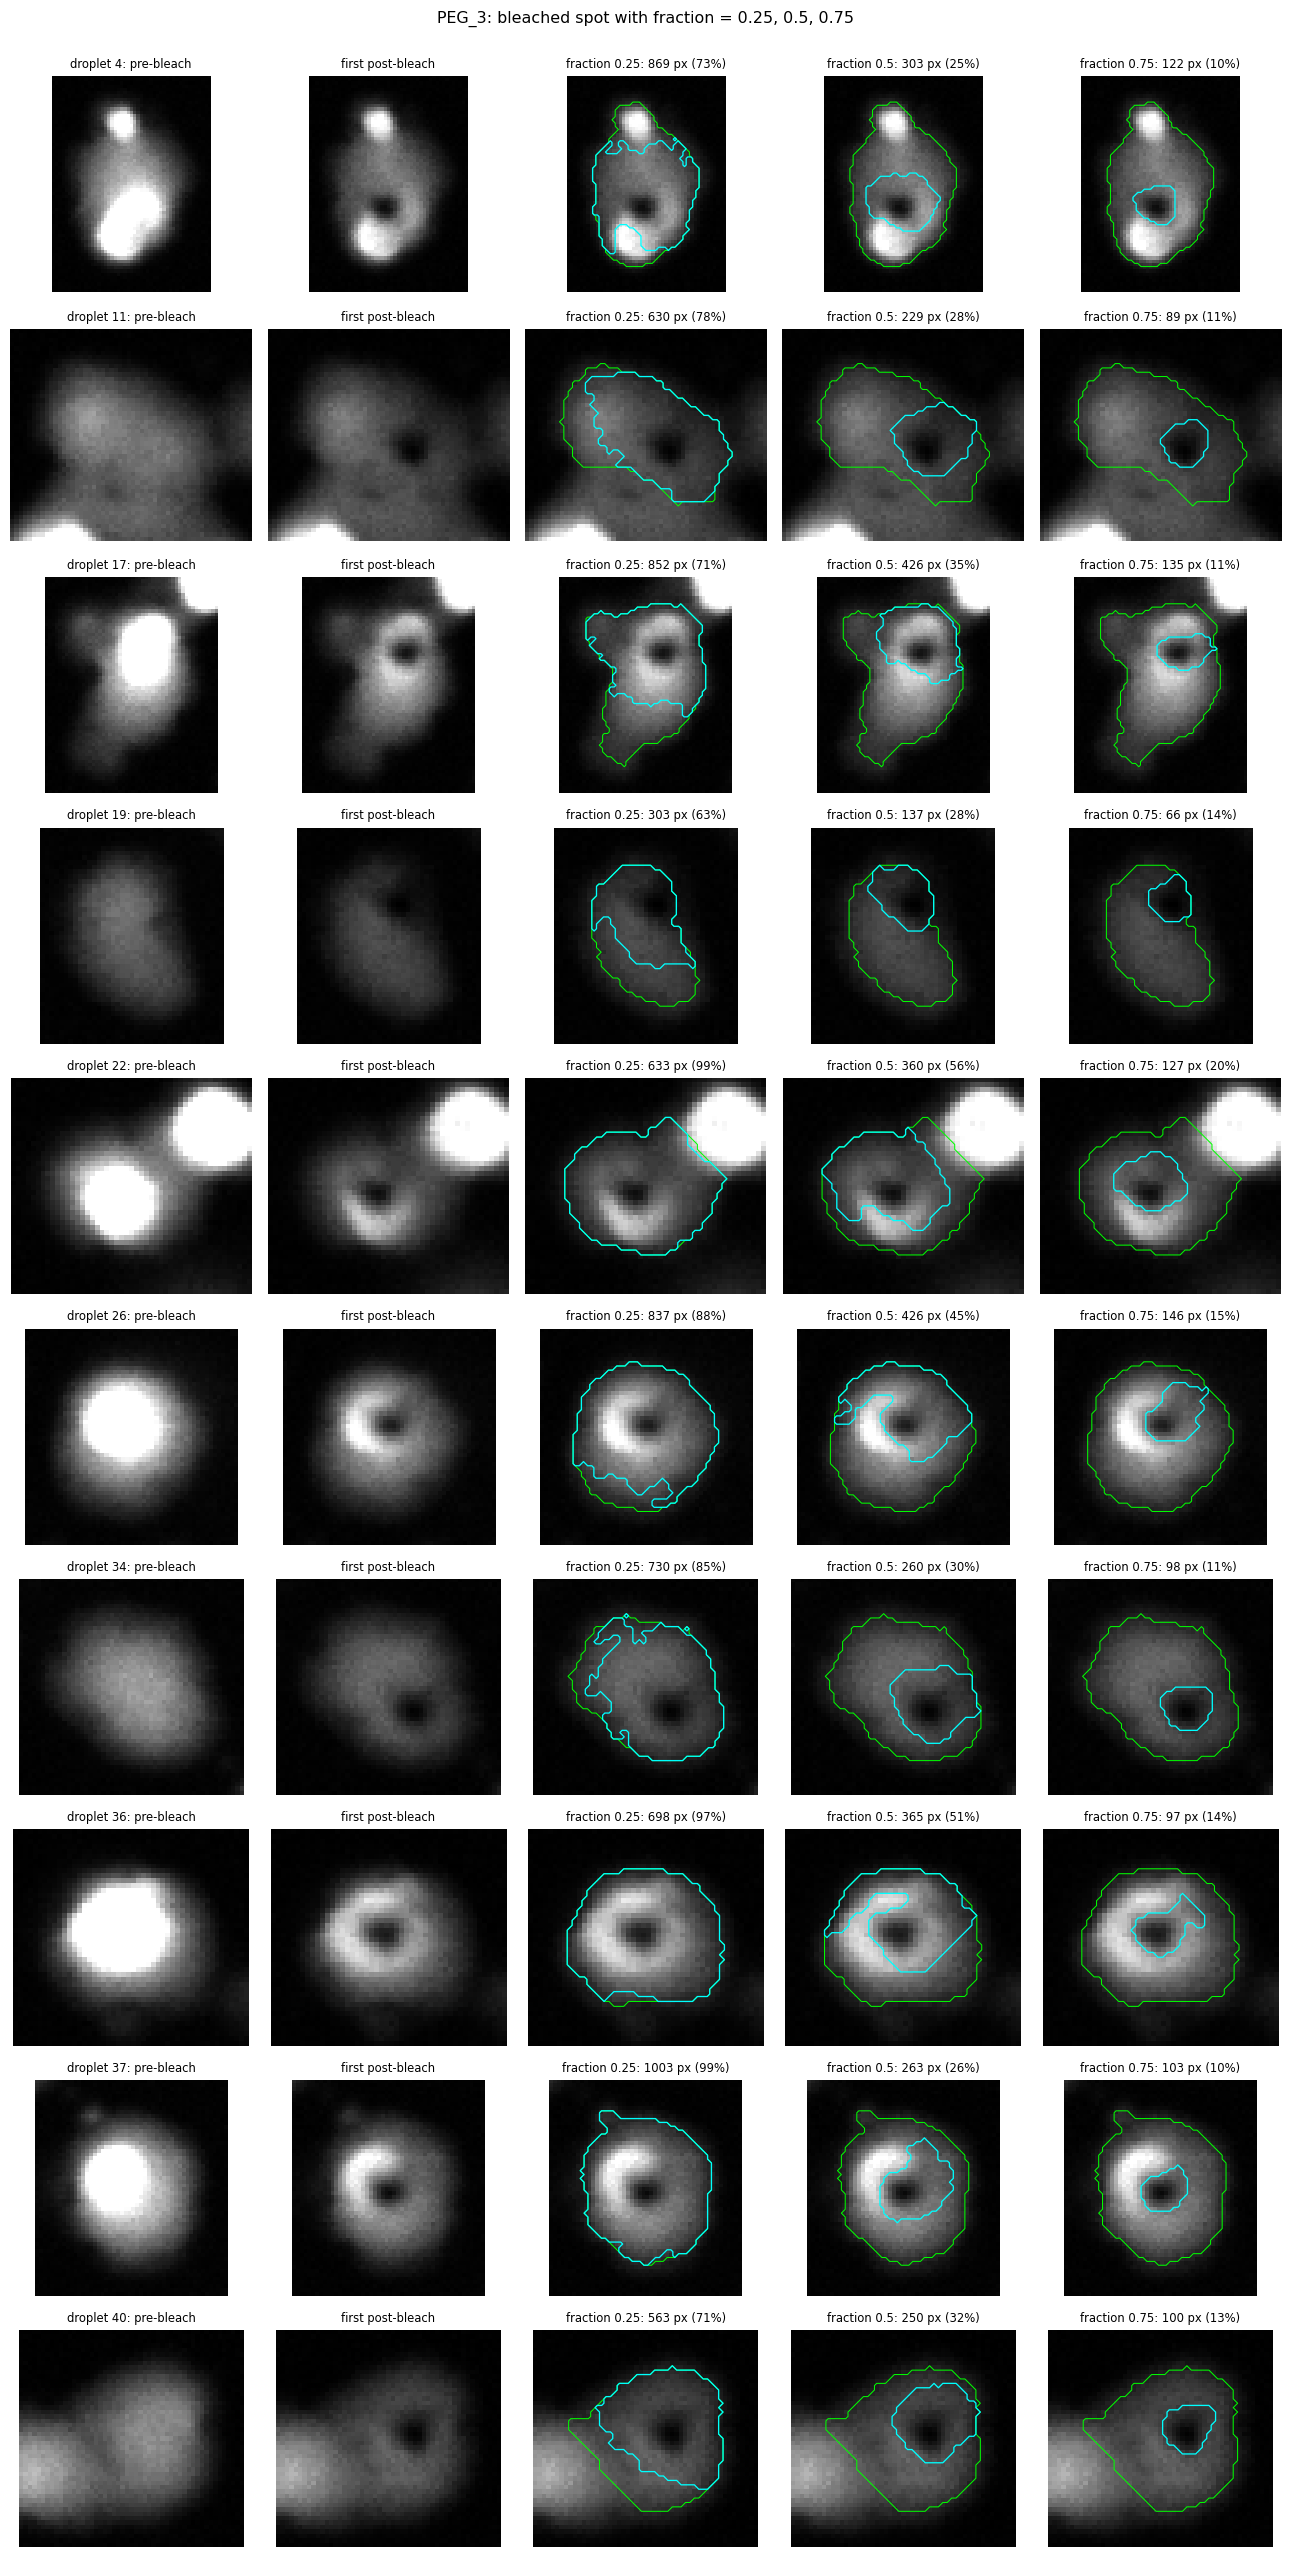

In [10]:
# Each row is a bleached droplet. Columns: the pre-bleach and first post-bleach frames
# without contours, then FRAME_SHOW with the spot edge for each fraction.
# Green = droplet, cyan = spot.

COMPARE_FRACTIONS = [0.25, 0.50, 0.75]
PAD = 8
FRAME_SHOW = FRAME_POST     # FRAME_PRE to see the contours on the pre-bleach frame
 
for name, ids in bleached.items():
    if not ids:
        continue
    labels = droplet_labels[name]
    pre, post = stacks[name][FRAME_PRE], stacks[name][FRAME_POST]
    img = stacks[name][FRAME_SHOW]
    lo, hi = np.percentile(pre, (1, 99.5))                       # same contrast in every panel
 
    n_cols = 2 + len(COMPARE_FRACTIONS)
    fig, axes = plt.subplots(len(ids), n_cols, squeeze=False,
                             figsize=(2.5 * n_cols, 2.5 * len(ids)))
    for i, d in enumerate(ids):
        r0, c0, r1, c1 = measure.regionprops((labels == d).astype(int))[0].bbox
        sl = (slice(max(r0 - PAD, 0), r1 + PAD), slice(max(c0 - PAD, 0), c1 + PAD))
        droplet_edge = (labels[sl] == d).astype(float)
 
        axes[i, 0].imshow(pre[sl], cmap="gray", vmin=lo, vmax=hi)
        axes[i, 0].set_title(f"droplet {d}: pre-bleach", fontsize=8)
        axes[i, 1].imshow(post[sl], cmap="gray", vmin=lo, vmax=hi)
        axes[i, 1].set_title("first post-bleach", fontsize=8)
        for j, fr in enumerate(COMPARE_FRACTIONS, start=2):
            spot = bleach_spot(drops[name], labels, d, fr)
            ax = axes[i, j]
            ax.imshow(img[sl], cmap="gray", vmin=lo, vmax=hi)
            ax.contour(droplet_edge, levels=[0.5], colors="lime", linewidths=0.7)
            ax.contour(spot[sl].astype(float), levels=[0.5], colors="cyan", linewidths=0.9)
            ax.set_title(f"fraction {fr}: {spot.sum()} px ({spot.sum() / (labels == d).sum():.0%})",
                         fontsize=8)
        for ax in axes[i]:
            ax.axis("off")
    fig.suptitle(f"{name}: bleached spot with fraction = "
                 + ", ".join(str(fr) for fr in COMPARE_FRACTIONS), fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.5 / fig.get_figheight()))   # leave room for the title
    plt.show()

# 3. Bleached droplets and bleached spots

In [11]:
SPOT_FRACTION = 0.75
 
spot_labels, spot_tables = {}, {}
for name, tab in tables.items():
    labels = droplet_labels[name]
    tab["bleached"] = tab["droplet"].isin(bleached[name])   # unbleached, static droplets
    spots = np.zeros_like(labels)
    rows = []
    for d in bleached[name]:
        spot = bleach_spot(drops[name], labels, d, SPOT_FRACTION)
        spots[spot] = d                                    # spot keeps the ID of its droplet
        droplet = labels == d
        edge = find_boundaries(droplet, mode="inner")      # outermost pixels of the droplet
        cy, cx = ndi.center_of_mass(droplet)
        sy, sx = ndi.center_of_mass(spot)
        rows.append({"droplet": d,
                     "droplet_area": int(droplet.sum()),
                     "spot_area": int(spot.sum()),
                     "spot_to_droplet_area": spot.sum() / droplet.sum(),
                     "bleach_depth": drops[name][spot].mean(),   
                     "spot_offset": np.hypot(sy - cy, sx - cx) / np.sqrt(droplet.sum() / np.pi),
                     "spot_touches_edge": bool((spot & edge).any())})
    spot_labels[name] = spots
    spot_tables[name] = pd.DataFrame(rows)
    print(f"\n{name}: {len(bleached[name])} bleached droplets")
    print(spot_tables[name].round(3).to_string(index=False))
 
# spot_to_droplet_area = fraction of the droplet inside the spot
# bleach_depth         =  mean relative drop in the spot, i.e. how deep the bleach is in the first post-bleach frame.
# spot_offset          = distance between spot and droplet centres / droplet radius (0 = centred)
# spot_touches_edge    = the spot reaches the droplet border


Apt2+Ca_2: 16 bleached droplets
 droplet  droplet_area  spot_area  spot_to_droplet_area  bleach_depth  spot_offset  spot_touches_edge
      12           408        158                 0.387         0.795        0.601               True
      21           504        118                 0.234         0.763        0.283               True
      26           748        191                 0.255         0.747        0.207               True
      34           481        124                 0.258         0.785        0.410               True
      35           475         99                 0.208         0.802        0.115              False
      36           522        174                 0.333         0.743        0.352               True
      40           513        171                 0.333         0.766        0.237               True
      56           579        153                 0.264         0.757        0.282              False
      61           620        203                

In [12]:
## Checks
#  
# Bleaching outside the segmented droplets
# A strong drop outside any droplet may mean a bleached droplet was excluded
# (e.g. it touched the image border) or not segmented.
CHECK_MIN_AREA = 20     # ignore tiny noisy patches
 
for name, stack in stacks.items():
    labels = droplet_labels[name]
    pre_s = filters.gaussian(stack[FRAME_PRE], sigma=SMOOTH_SIGMA, preserve_range=True)
    post_s = filters.gaussian(stack[FRAME_POST], sigma=SMOOTH_SIGMA, preserve_range=True)
    typical_signal = np.median(pre_s[labels > 0])                     # typical droplet intensity
    outside = ndi.distance_transform_edt(labels == 0) > 2             # skip droplet edges
    strong = outside & ((pre_s - post_s) > MIN_PEAK_DROP * typical_signal)
    lab = measure.label(strong, connectivity=2)
    n = sum(r.area >= CHECK_MIN_AREA for r in measure.regionprops(lab))
    print(f"{name}: {n} region(s) with strong bleaching outside the droplet labels")

Apt2+Ca_2: 0 region(s) with strong bleaching outside the droplet labels
Apt2_1: 0 region(s) with strong bleaching outside the droplet labels
PEG_3: 0 region(s) with strong bleaching outside the droplet labels


# 4. Overview

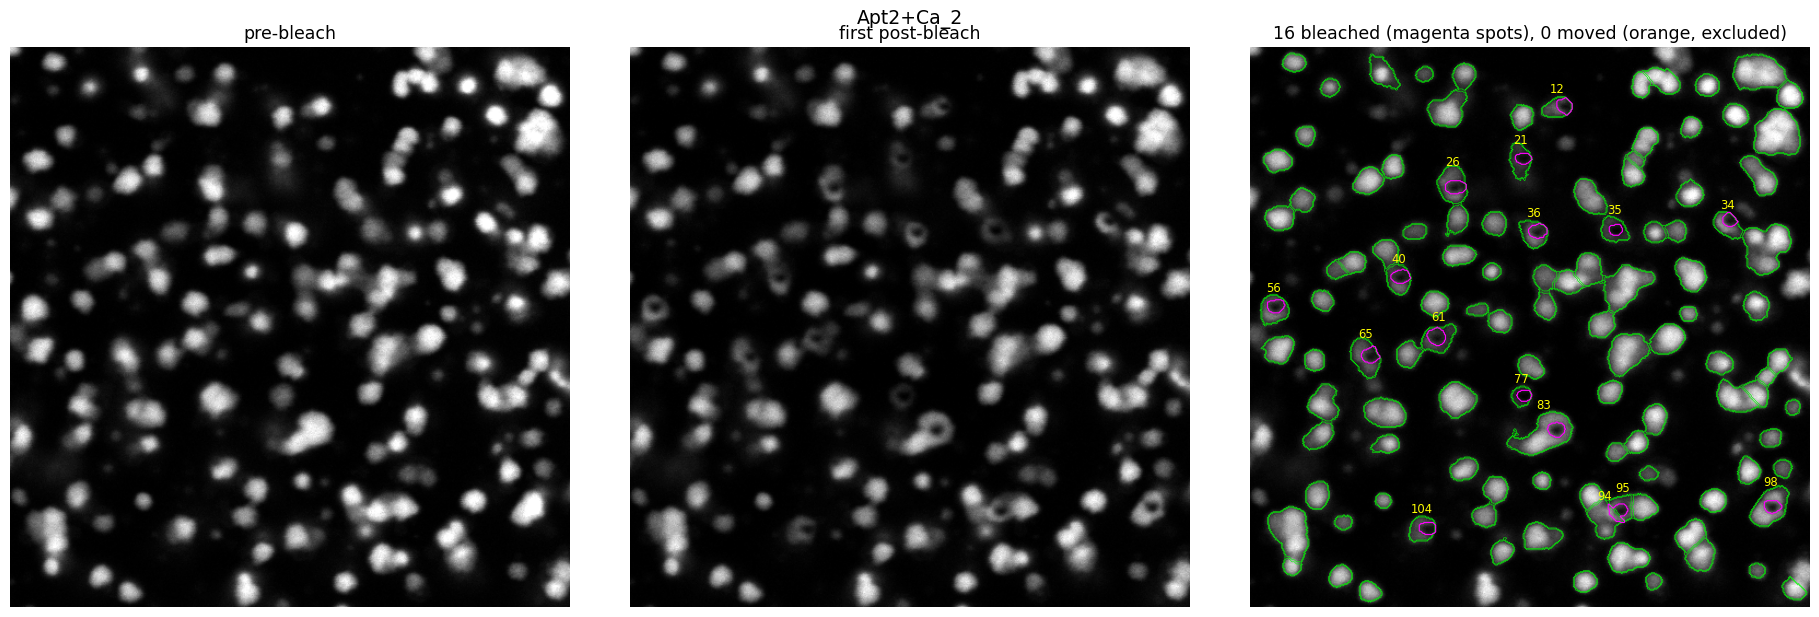

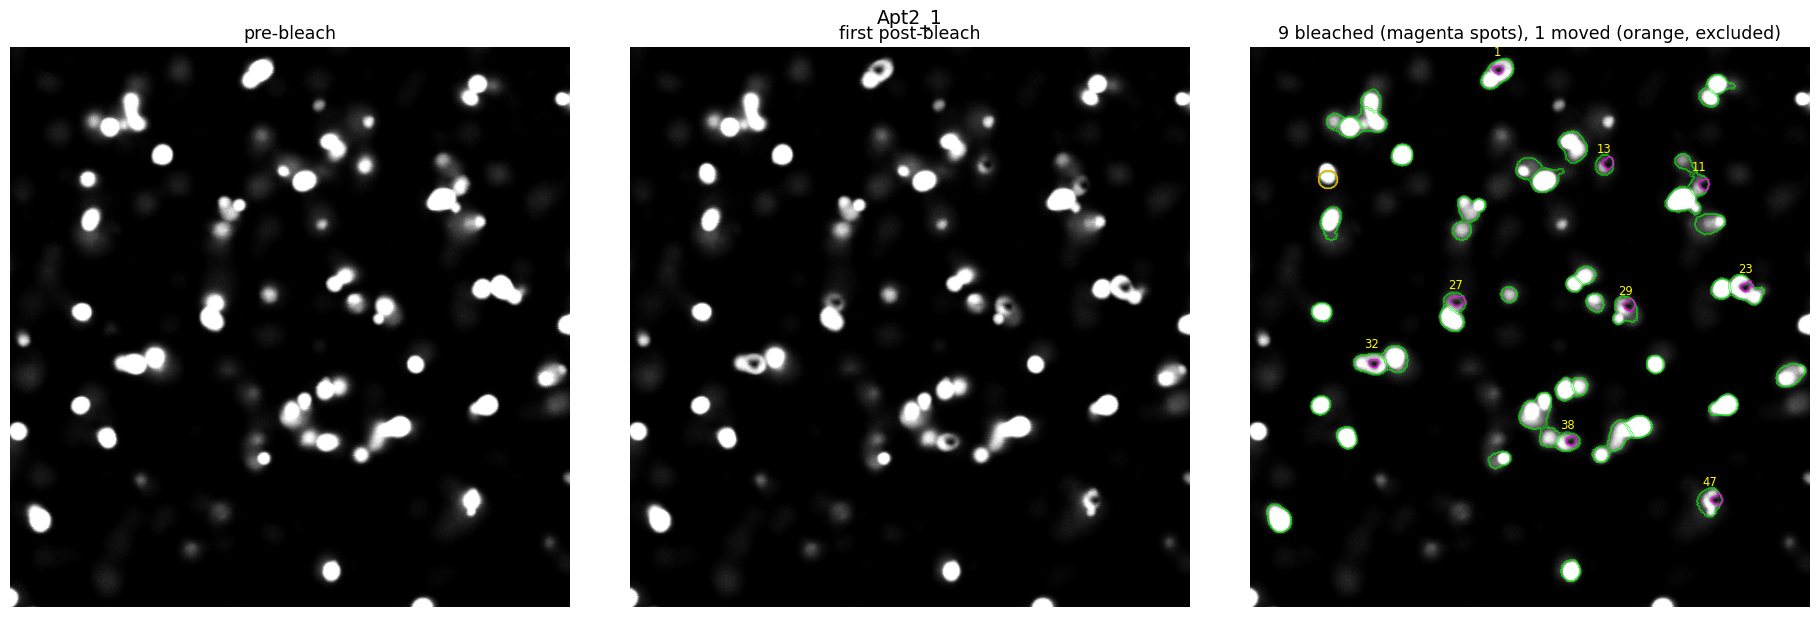

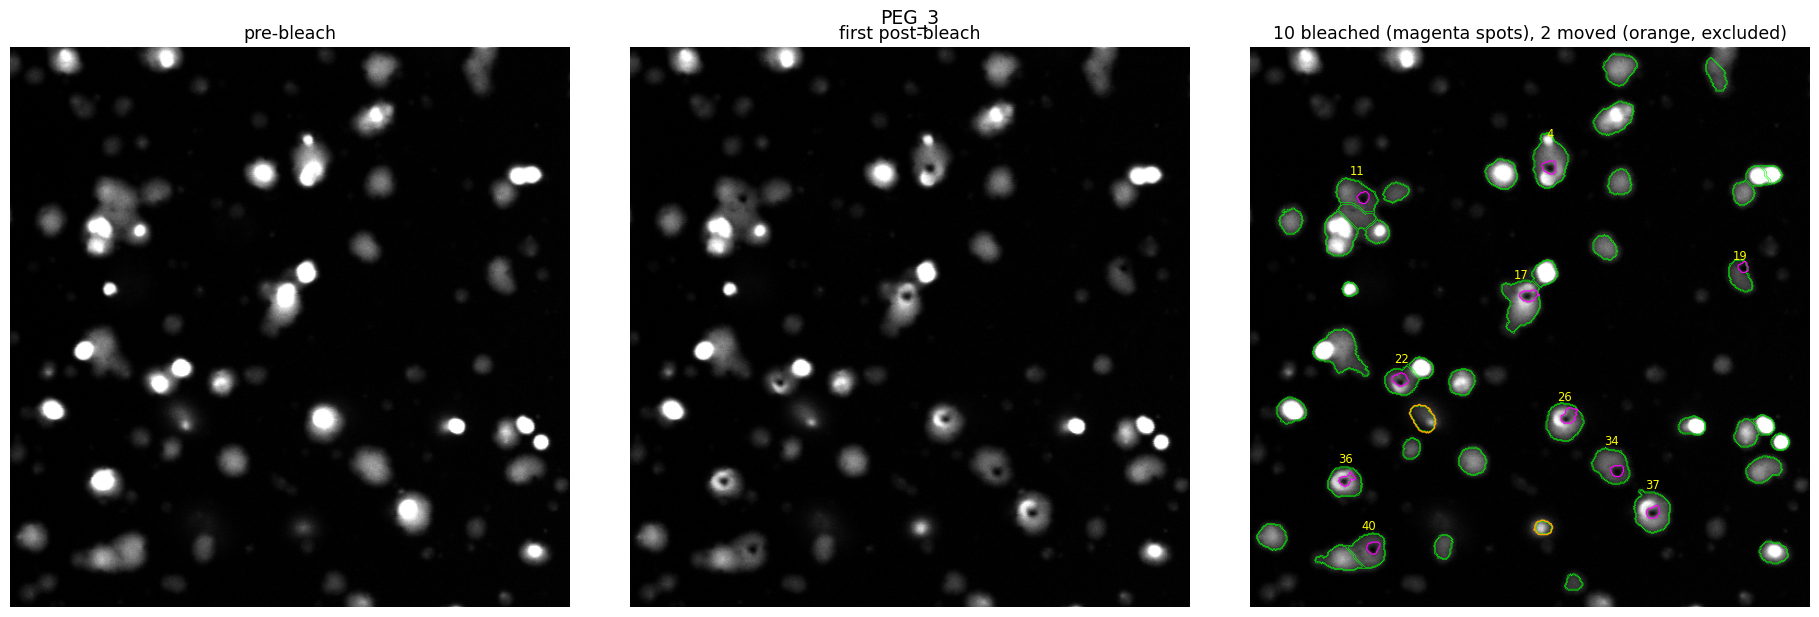

In [13]:
for name, stack in stacks.items():
    labels, spots, tab = droplet_labels[name], spot_labels[name], tables[name]
    pre, post = stack[FRAME_PRE], stack[FRAME_POST]
    lo, hi = np.percentile(pre, (1, 99.5))                          # same contrast pre and post
    moved = np.isin(labels, tab.loc[tab["moved"], "droplet"].values)
 
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(pre, cmap="gray", vmin=lo, vmax=hi); axes[0].set_title("pre-bleach")
    axes[1].imshow(post, cmap="gray", vmin=lo, vmax=hi); axes[1].set_title("first post-bleach")
    axes[2].imshow(post, cmap="gray", vmin=lo, vmax=hi)
    axes[2].contour(find_boundaries(labels, mode="inner").astype(float), levels=[0.5],
                    colors="lime", linewidths=0.4)
    if moved.any():
        axes[2].contour(moved.astype(float), levels=[0.5], colors="orange", linewidths=1.0)
    if spots.any():
        axes[2].contour((spots > 0).astype(float), levels=[0.5], colors="magenta", linewidths=0.8)
    for r in measure.regionprops(labels * np.isin(labels, bleached[name])):   # IDs of bleached droplets
        axes[2].text(r.centroid[1], r.centroid[0] - np.sqrt(r.area / np.pi) - 3, str(r.label),
                     color="yellow", fontsize=8, ha="center")
    axes[2].set_title(f"{len(bleached[name])} bleached (magenta spots), "
                      f"{tab['moved'].sum()} moved (orange, excluded)")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(name, fontsize=13)
    plt.tight_layout(); plt.show()

# 5. Save Results

In [ ]:
BLEACH_DIR = Path("results/bleach_detect")
BLEACH_DIR.mkdir(parents=True, exist_ok=True)

for name in stacks:
    tifffile.imwrite(BLEACH_DIR / f"{name}_spot_labels.tif", spot_labels[name].astype(np.uint16))
    spot_tables[name].to_csv(BLEACH_DIR / f"{name}_bleached_droplets.csv", index=False)
    tables[name].to_csv(BLEACH_DIR / f"{name}_all_droplets.csv", index=False)   # includes moved, bleached
    
with open(BLEACH_DIR / "bleach_parameters.json", "w") as fh:
    json.dump({"frame_pre": FRAME_PRE, "frame_post": FRAME_POST,
               "smooth_sigma": SMOOTH_SIGMA, "background_subtraction": False,
               "territory": TERRITORY, "gain_frac": GAIN_FRAC, "max_shift": MAX_SHIFT,
               "min_peak_drop": MIN_PEAK_DROP, "spot_fraction": SPOT_FRACTION}, fh, indent=2)

saved to results/bleach_detect
